In [3]:
import pandas as pd
import numpy as np
from collections import Counter

# Helper function to calculate entropy
def calculate_entropy(data):
    if len(data) == 0:
        return 0

    # Count occurrences of each class label
    class_labels = data.iloc[:, -1] # Assuming last column is the target class
    label_counts = Counter(class_labels)

    entropy = 0
    for label in label_counts:
        probability = label_counts[label] / len(class_labels)
        entropy -= probability * np.log2(probability)
    return entropy

# Helper function to calculate information gain
def calculate_information_gain(data, attribute_name, target_attribute_name):
    total_entropy = calculate_entropy(data[[target_attribute_name]])

    # Calculate entropy for each value of the attribute
    attribute_values = data[attribute_name].unique()
    weighted_average_entropy = 0
    for value in attribute_values:
        subset = data[data[attribute_name] == value]
        probability = len(subset) / len(data)
        weighted_average_entropy += probability * calculate_entropy(subset[[target_attribute_name]])

    information_gain = total_entropy - weighted_average_entropy
    return information_gain

# Node class for the Decision Tree
class Node:
    def __init__(self, attribute=None, value=None, result=None, children=None):
        self.attribute = attribute    # Attribute to split on
        self.value = value        # Value of the parent attribute that leads to this node
        self.result = result      # Class label if it's a leaf node
        self.children = children if children is not None else {} # Dictionary of child nodes

    def __repr__(self):
        if self.result is not None:
            return f"Leaf({self.result})"
        return f"Node({self.attribute}, Children: {list(self.children.keys())})"

# ID3 Algorithm implementation
def id3(data, target_attribute_name, attributes):
    # If all examples have the same target value, return a leaf node with that value
    target_values = data[target_attribute_name].unique()
    if len(target_values) == 1:
        return Node(result=target_values[0])

    # If there are no more attributes to split on, return a leaf node with the most common target value
    if not attributes:
        most_common_target = data[target_attribute_name].mode()[0]
        return Node(result=most_common_target)

    # Select the best attribute to split on (attribute with highest information gain)
    best_attribute = None
    max_info_gain = -1
    for attr in attributes:
        info_gain = calculate_information_gain(data, attr, target_attribute_name)
        if info_gain > max_info_gain:
            max_info_gain = info_gain
            best_attribute = attr

    # Create a new decision node
    node = Node(attribute=best_attribute)

    # Remove the best attribute from the list of available attributes
    remaining_attributes = [attr for attr in attributes if attr != best_attribute]

    # For each value of the best attribute, create a child branch
    for value in data[best_attribute].unique():
        subset = data[data[best_attribute] == value]
        if not subset.empty:
            child_node = id3(subset, target_attribute_name, remaining_attributes)
            child_node.value = value # Store the value that led to this child
            node.children[value] = child_node
        else:
            # If a subset is empty, create a leaf node with the most common target value from the parent
            most_common_target = data[target_attribute_name].mode()[0]
            node.children[value] = Node(result=most_common_target, value=value)

    return node

# Function to predict a class for a new instance
def predict(tree, instance):
    if tree.result is not None:
        return tree.result

    attribute_value = instance[tree.attribute]
    if attribute_value in tree.children:
        return predict(tree.children[attribute_value], instance)
    else:
        # Handle cases where the instance has an unknown attribute value
        # For simplicity, returning None or the most common class from the tree's children
        # In a real scenario, more robust handling would be needed.
        return None



In [4]:
# Sample dataset (Weather for playing golf)
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast', 'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Strong'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}
df = pd.DataFrame(data)

print("Dataset:")
display(df)

target_attribute = 'PlayTennis'
attributes = [col for col in df.columns if col != target_attribute]

# Build the ID3 tree
print("\nBuilding Decision Tree...")
id3_tree = id3(df, target_attribute, attributes)
print("Decision Tree built successfully!")

# Function to print the tree (for visualization)
def print_tree(node, depth=0, branch_value=None):
    indent = "  " * depth
    if branch_value is not None:
        branch_str = f"Branch ({branch_value}): "
    else:
        branch_str = ""

    if node.result is not None:
        print(f"{indent}{branch_str}Predict: {node.result}")
    else:
        print(f"{indent}{branch_str}Split on: {node.attribute}")
        for value, child in node.children.items():
            print_tree(child, depth + 1, value)

print("\nDecision Tree Structure:")
print_tree(id3_tree)

# Make predictions
print("\nMaking Predictions:")
new_instance1 = pd.Series({'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'})
prediction1 = predict(id3_tree, new_instance1)
print(f"Instance: {new_instance1.to_dict()} -> Prediction: {prediction1}")

new_instance2 = pd.Series({'Outlook': 'Rain', 'Temperature': 'Hot', 'Humidity': 'Normal', 'Wind': 'Weak'})
prediction2 = predict(id3_tree, new_instance2)
print(f"Instance: {new_instance2.to_dict()} -> Prediction: {prediction2}")

Dataset:


,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes



Building Decision Tree...
Decision Tree built successfully!

Decision Tree Structure:
Split on: Outlook
  Branch (Sunny): Split on: Humidity
    Branch (High): Predict: No
    Branch (Normal): Predict: Yes
  Branch (Overcast): Predict: Yes
  Branch (Rain): Split on: Wind
    Branch (Weak): Predict: Yes
    Branch (Strong): Predict: No

Making Predictions:
Instance: {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'} -> Prediction: No
Instance: {'Outlook': 'Rain', 'Temperature': 'Hot', 'Humidity': 'Normal', 'Wind': 'Weak'} -> Prediction: Yes


In [7]:
import numpy as np
import matplotlib.pyplot as plt

class KMeans:
    def __init__(self, k=3, max_iters=100):
        self.k = k
        self.max_iters = max_iters
        self.centroids = None

    def fit(self, X):
        # Randomly initialize centroids from the data points
        random_indices = np.random.choice(len(X), self.k, replace=False)
        self.centroids = X[random_indices]

        for _ in range(self.max_iters):
            # Assign clusters based on nearest centroid
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            labels = np.argmin(distances, axis=1)

            # Calculate new centroids
            new_centroids = np.array([X[labels == i].mean(axis=0) if len(X[labels == i]) > 0 else self.centroids[i] for i in range(self.k)])

            # Check for convergence
            if np.all(self.centroids == new_centroids):
                break
            self.centroids = new_centroids

        return labels

### Testing and Visualizing K-Means

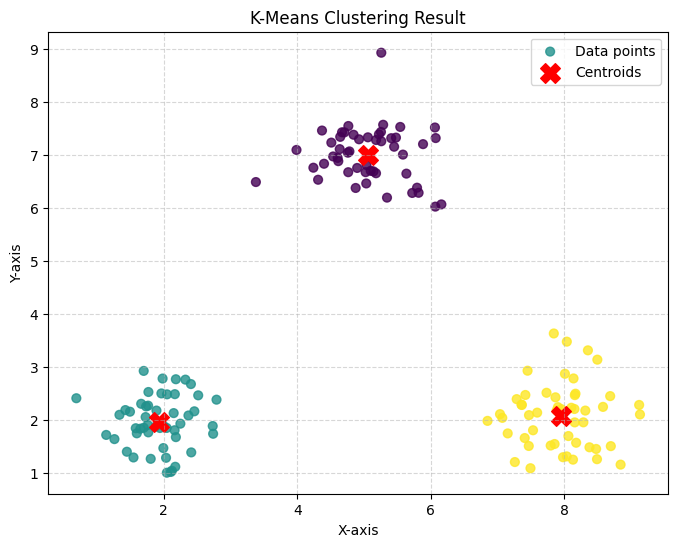

In [8]:
# Generate synthetic 2D cluster data
np.random.seed(42)
group1 = np.random.normal(loc=[2, 2], scale=0.5, size=(50, 2))
group2 = np.random.normal(loc=[8, 2], scale=0.6, size=(50, 2))
group3 = np.random.normal(loc=[5, 7], scale=0.5, size=(50, 2))
X = np.vstack([group1, group2, group3])

# Fit K-Means model
kmeans = KMeans(k=3)
labels = kmeans.fit(X)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=40, alpha=0.8, label='Data points')
plt.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering Result')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()